In [1]:
from langgraph.graph import StateGraph, END, START
from typing import TypedDict
from pydantic import BaseModel, Field
from langchain_ollama import ChatOllama
import httpx

In [2]:
def print_workflow_info(workflow, app=None):
    """Print comprehensive information about a LangGraph workflow."""
    print("WORKFLOW INFORMATION")
    print("====================")
    print(f"Nodes: {workflow.nodes}")
    print(f"Edges: {workflow.edges}")

    try:
        finish_points = workflow.finish_points
        print(f"Finish points: {finish_points}")
    except:
        try:
            print(f"Finish point: {workflow._finish_point}")
        except:
            print("Finish points attribute not directly accessible")

    if app:
        print("\nWorkflow Visualization:")
        from IPython.display import display
        display(app.get_graph().draw_png())

In [3]:
client = httpx.Client(verify=False)
llm = ChatOllama(model="qwen3.5:2b", http_client=client)

In [4]:
class ChainState(TypedDict):
    job_description: str
    resume_summary: str
    cover_letter: str

- Resume Summary Agent

In [5]:
def generate_resume_summary(state: ChainState) -> ChainState:
    prompt = f"""
    You are a resume assistant. Read the following job description and summarize the key qualifications and experience the ideal candidate should have, phrased as if from the perspective of strong applicant's resume summary.
    
    job_Description:
    {state['job_description']}
    """

    response = llm.invoke(prompt)
    return {**state, "resume_summary": response.content}

- Generate Cover Letter Agent

In [6]:
def generate_cover_letter(state: ChainState) -> ChainState:
    prompt = f"""
    You are a cover letter writing assistant. Using the resume summary below, write a professional and personalized cover letter for following job.

    Resume_Summary:
    {state['resume_summary']}

    Job_Description:
    {state['job_description']}
    """

    response = llm.invoke(prompt)

    return {**state, "cover_letter": response.content}

- LangGraph Workflow

In [7]:
workflow = StateGraph(ChainState)
workflow

In [8]:
workflow.add_node("generate_resume_summary",generate_resume_summary)
workflow.add_node("generate_cover_letter",generate_cover_letter)

In [9]:
workflow.set_entry_point("generate_resume_summary")

In [10]:
workflow.add_edge("generate_resume_summary","generate_cover_letter")

In [11]:
workflow.set_finish_point("generate_cover_letter")

In [12]:
print_workflow_info(workflow)

WORKFLOW INFORMATION
Nodes: {'generate_resume_summary': StateNodeSpec(runnable=generate_resume_summary(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None, input_schema=<class '__main__.ChainState'>, retry_policy=None, cache_policy=None, is_error_handler=False, error_handler_node=None, ends=(), defer=False, timeout=None, trace_policy=None), 'generate_cover_letter': StateNodeSpec(runnable=generate_cover_letter(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None, input_schema=<class '__main__.ChainState'>, retry_policy=None, cache_policy=None, is_error_handler=False, error_handler_node=None, ends=(), defer=False, timeout=None, trace_policy=None)}
Edges: {('generate_cover_letter', '__end__'), ('generate_resume_summary', 'generate_cover_letter'), ('__start__', 'generate_resume_summary')}
Finish points attribute not directly accessible


In [13]:
app =workflow.compile()

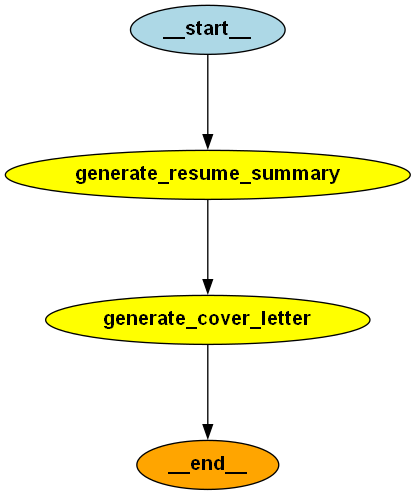

In [14]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_png()))

In [15]:
input_state = {
        "job_description": "We are looking for a data scientist with experience in machine learning, NLP, and Python. Prior work with large datasets and experience deploying models into production is required."
}

result = app.invoke(input_state)

In [16]:
result['resume_summary']

'Results-driven Data Scientist specializing in Machine Learning and Natural Language Processing (NLP), with extensive proficiency in Python. I possess deep expertise in leveraging large-scale datasets for advanced model training and feature engineering. A standout skill is successfully translating complex algorithms into robust, production-ready applications, ensuring high accuracy while maintaining scalability.'